In [8]:
from google.colab import files

uploaded = files.upload()  # Select kaggle.json from your computer

Saving rainfall.csv to rainfall (2).csv


In [9]:
import os

print("Current directory files:", os.listdir("/content"))
print("Kaggle config exists:", os.path.exists("/root/.kaggle/kaggle.json"))

Current directory files: ['.config', 'rainfall.csv', 'archive (2).zip', 'rainfall (1).csv', 'rainfall (2).csv', 'sample_data']
Kaggle config exists: False


## ⚙️ Configure Kaggle API

In [10]:
import os
import shutil

# Create Kaggle directory
os.makedirs("/root/.kaggle", exist_ok=True)

# Move kaggle.json only if it is not already there
if os.path.exists("/content/kaggle.json"):
    shutil.move(
        "/content/kaggle.json",
        "/root/.kaggle/kaggle.json"
    )
elif os.path.exists("/root/.kaggle/kaggle.json"):
    print("kaggle.json is already in the correct location.")
else:
    print("Error: kaggle.json was not found. Upload it again.")

# Set permissions if the file exists
if os.path.exists("/root/.kaggle/kaggle.json"):
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    print("Kaggle API configured successfully!")

Error: kaggle.json was not found. Upload it again.


## 📥 Download Dataset from Kaggle

Dataset: Simple Rainfall Classification Dataset

In [11]:
!pip install -q kaggle

In [12]:
!kaggle datasets download -d sujithmandala/simple-rainfall-classification-dataset

Dataset URL: https://www.kaggle.com/datasets/sujithmandala/simple-rainfall-classification-dataset
License(s): CC-BY-SA-4.0
100% 804/804 [00:00<00:00, 2.47MB/s]



## 📦 Extract Dataset

In [13]:
import zipfile

with zipfile.ZipFile('simple-rainfall-classification-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('rainfall_dataset')

## 📊 Load Dataset into Pandas

In [14]:
import os

print(os.listdir('rainfall_dataset'))

['rainfall.csv']


In [15]:
import pandas as pd

# Replace filename with the actual CSV name printed above
df = pd.read_csv('rainfall_dataset/rainfall.csv')

print(df.head())
print(df.shape)

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
(54, 6)


## 🔍 Basic Structure Check

In [16]:
# Shape of dataset
df.shape

# Column names
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

## 🎯 Objective
In this step, we will:
- Understand dataset structure
- Check data types
- Identify missing values
- Generate statistical summary

## 🔍 View Dataset
Display first and last few records

In [17]:
# First 5 rows
df.head()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


In [18]:
# Last 5 rows
df.tail()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
49,2022-02-19,17.3,15.9,83.0,8.6,Rainy
50,2022-02-20,9.6,18.6,71.0,6.7,Rainy
51,2022-02-21,0.0,21.3,55.0,5.1,Sunny
52,2022-02-22,7.4,16.8,77.0,8.9,Rainy
53,Co,NaN,NaN,NaN,NaN,NaN


## 📐 Dataset Shape
Check number of rows and columns

In [19]:
print("Rows and Columns:", df.shape)

Rows and Columns: (54, 6)


## 🏷 Column Names
List all available features

In [20]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')


## 🔢 Data Types
Understand numeric and categorical columns

In [21]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


## ℹ Dataset Information
Summary of memory usage and non-null values

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               54 non-null     object 
 1   rainfall           53 non-null     float64
 2   temperature        53 non-null     float64
 3   humidity           53 non-null     float64
 4   wind_speed         53 non-null     float64
 5   weather_condition  53 non-null     object 
dtypes: float64(4), object(2)
memory usage: 2.7+ KB


## ❓ Missing Values Check
Find null values in each column

In [23]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


## 📊 Statistical Summary
Numerical overview of dataset

In [24]:
df.describe()

,rainfall,temperature,humidity,wind_speed
count,53.000000,53.000000,53.000000,53.000000
mean,9.049057,17.950943,69.245283,6.403774
std,6.712521,2.500663,11.969361,2.209069
min,0.000000,13.900000,44.000000,2.100000
25%,3.900000,16.100000,62.000000,4.700000
50%,8.300000,17.800000,72.000000,6.700000
75%,14.800000,19.400000,78.000000,8.300000
max,21.800000,23.400000,89.000000,10.500000


## 🧠 Initial Observations
While exploring, observe:
- Which columns are numerical
- Which columns are categorical
- Any missing values
- Minimum and maximum values
- Possible outliers

## ✅ Outcome

After this step, we understand:
- Dataset structure
- Data quality
- Feature types
- Summary statistics

#Correlation Analysis

## 🎯 Objective
In this step, we will:
- Understand relationships between numerical features
- Identify strong positive/negative correlations
- Detect multicollinearity

## 📌 What is Correlation?

Correlation measures how strongly two variables are related.

- +1 → Strong positive relationship
- -1 → Strong negative relationship
- 0 → No relationship

## 🔢 Compute Correlation Matrix

In [25]:
# Compute correlation matrix (only numeric columns)
corr_matrix = df.corr(numeric_only=True)

corr_matrix

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


## 🎨 Visualize Correlation using Heatmap

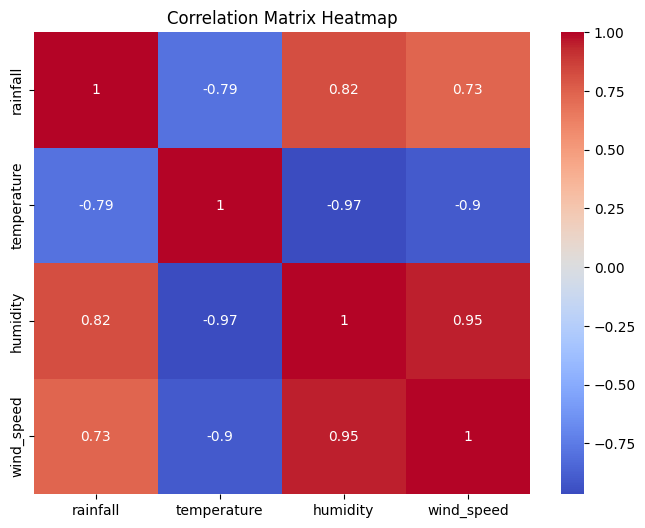

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

## 🔍 Focus on Target Variable

Check how features relate to the target (e.g., rainfall)

In [27]:
# Replace 'rainfall' with your target column if different
corr_matrix["rainfall"].sort_values(ascending=False)

,rainfall
rainfall,1.000000
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


## ⚠️ Detect Multicollinearity

Highly correlated features can affect model performance

In [28]:
# Find highly correlated feature pairs (> 0.8)
high_corr = []

for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i != j and abs(corr_matrix[i][j]) > 0.8:
            high_corr.append((i, j, corr_matrix[i][j]))

high_corr

[('rainfall', 'humidity', np.float64(0.8213569723603099)),
 ('temperature', 'humidity', np.float64(-0.9660971268282758)),
 ('temperature', 'wind_speed', np.float64(-0.9029958088261343)),
 ('humidity', 'rainfall', np.float64(0.8213569723603099)),
 ('humidity', 'temperature', np.float64(-0.9660971268282758)),
 ('humidity', 'wind_speed', np.float64(0.9516425912012718)),
 ('wind_speed', 'temperature', np.float64(-0.9029958088261343)),
 ('wind_speed', 'humidity', np.float64(0.9516425912012718))]

## 🧠 Observations to Make

- Which features strongly affect rainfall?
- Are there strong positive or negative correlations?
- Any redundant features (multicollinearity)?

#Distribution Analysis

## 🎯 Objective
In this step, we will:
- Understand how data is distributed
- Identify skewness (left/right)
- Detect outliers
- Analyze spread of data

## 📌 What is Distribution?

Distribution shows how values of a variable are spread.

We analyze:
- Shape (Normal / Skewed)
- Spread (Variance)
- Outliers

## 📊 Histogram (Distribution of Features)

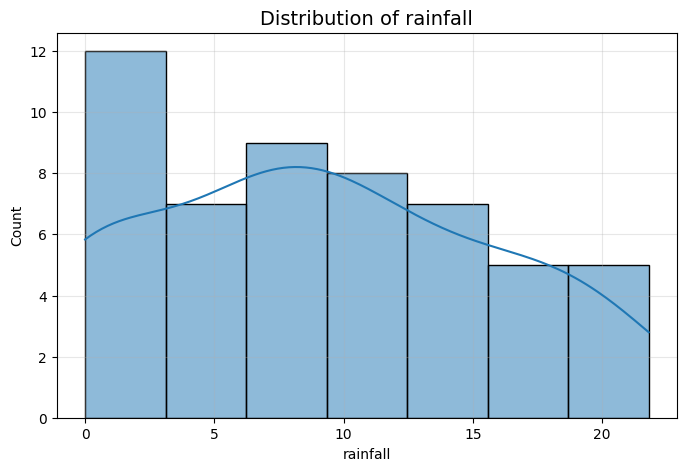

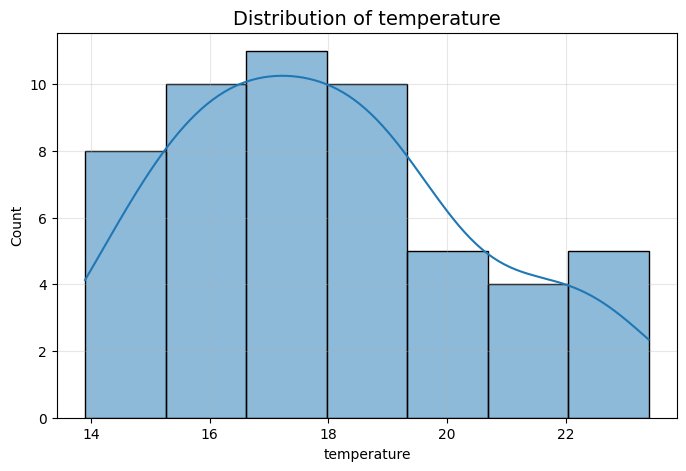

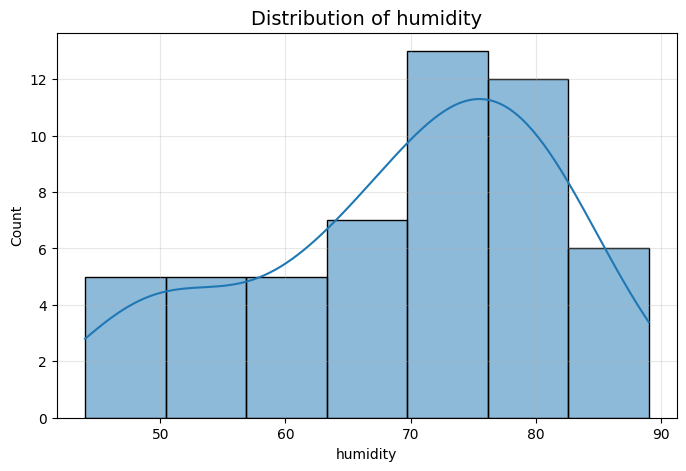

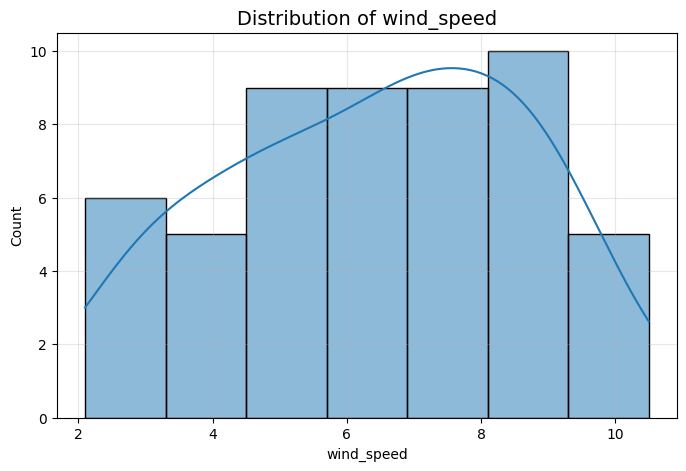

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8,5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)

    plt.show()

## 🔍 Observations from Histogram

- Is data symmetric?
- Is it skewed (left/right)?
- Are values concentrated or spread out?

## 📦 Boxplot (Outlier Detection)

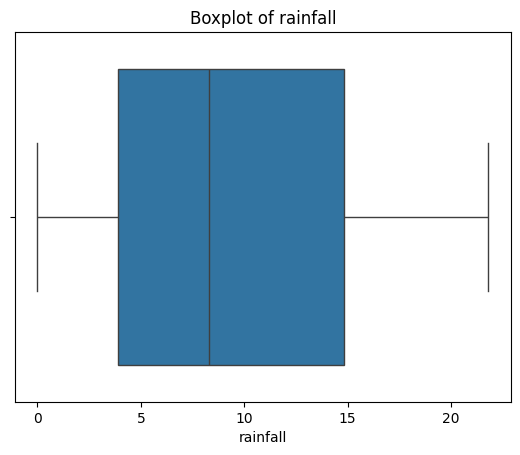

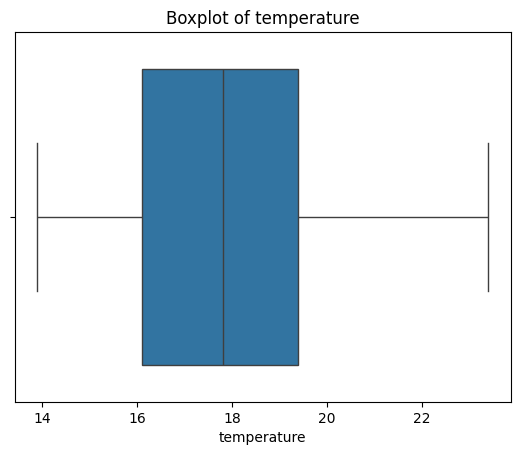

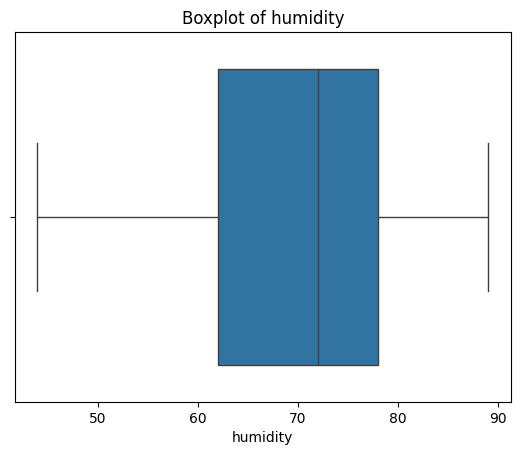

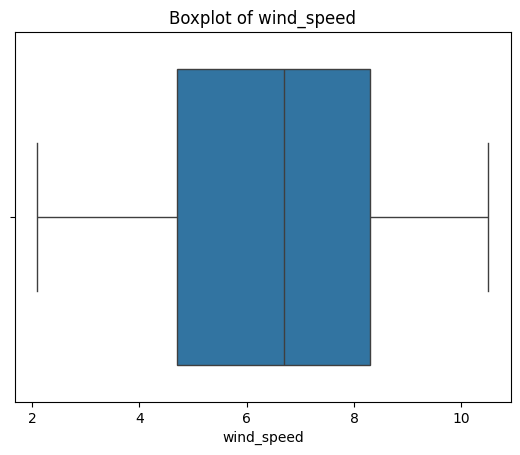

In [30]:
import seaborn as sns

# Boxplot for each numeric column
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## ⚠️ Observations from Boxplot

- Points outside whiskers = Outliers
- Helps detect extreme values

## 📈 KDE Plot (Smooth Distribution Curve)

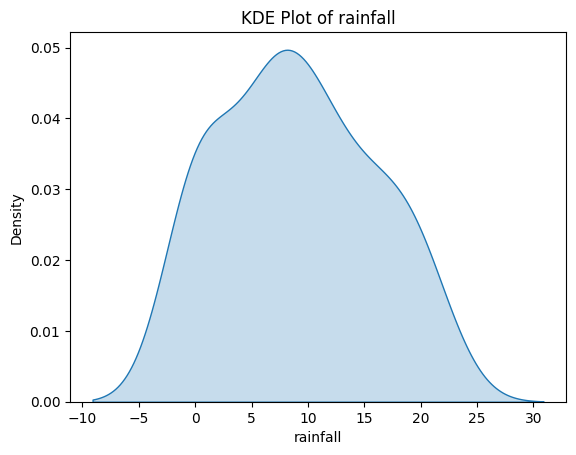

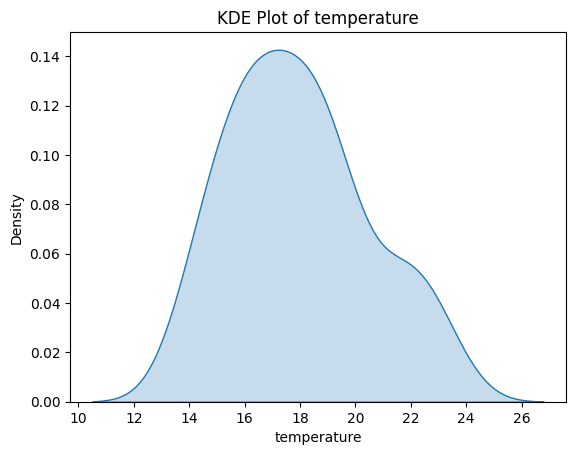

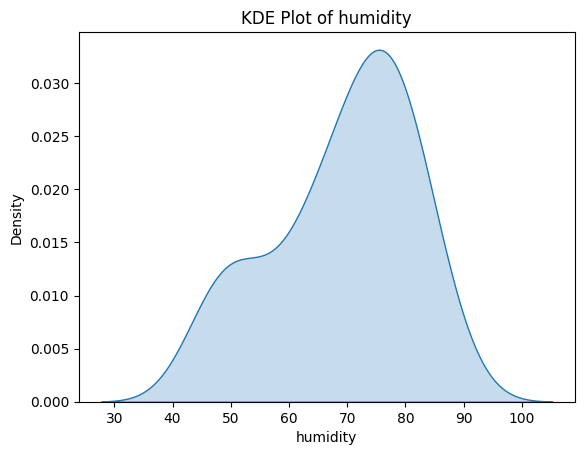

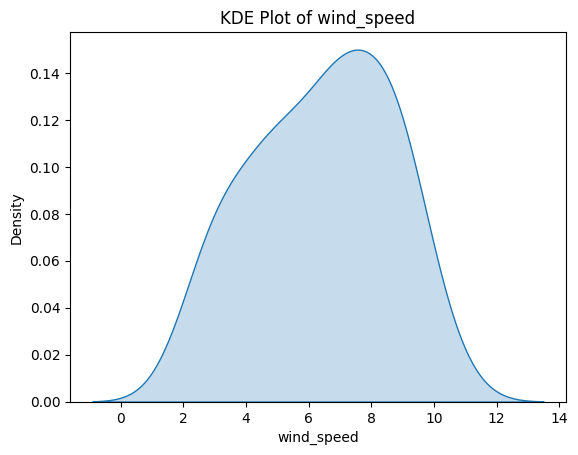

In [31]:
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

## 🔢 Skewness Calculation

In [32]:
# Calculate skewness
df.skew(numeric_only=True)

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


## 📌 Interpretation of Skewness

- Skew = 0 → Normal distribution
- Skew > 0 → Right skewed
- Skew < 0 → Left skewed

## 🧠 Observations to Make

- Which features are skewed?
- Are there outliers present?
- Which features are normally distributed?
- Any imbalance in values?

#Insights Extraction & Conclusion

## 🎯 Objective
In this step, we will:
- Derive meaningful insights from EDA
- Summarize key findings
- Understand feature impact on target

## 📌 What are Insights?

Insights are meaningful conclusions derived from data analysis.

They answer:
- What is happening?
- Why is it happening?
- What can we do next?

## 🔍 Basic Aggregations

In [33]:
# Example statistics
print("Average Rainfall:", df["rainfall"].mean())
print("Maximum Rainfall:", df["rainfall"].max())
print("Minimum Rainfall:", df["rainfall"].min())

Average Rainfall: 9.049056603773584
Maximum Rainfall: 21.8
Minimum Rainfall: 0.0


## 📊 Group-wise Analysis
Analyze how features affect the target

In [34]:
# Average rainfall by weather condition
if "weather_condition" in df.columns and "rainfall" in df.columns:

    avg_rainfall = df.groupby("weather_condition")["rainfall"].mean()

    print("Average Rainfall by Weather Condition:")
    print(avg_rainfall)

else:
    print("Required columns not found in the dataset.")

Average Rainfall by Weather Condition:
weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


## 📈 Feature vs Target Insights

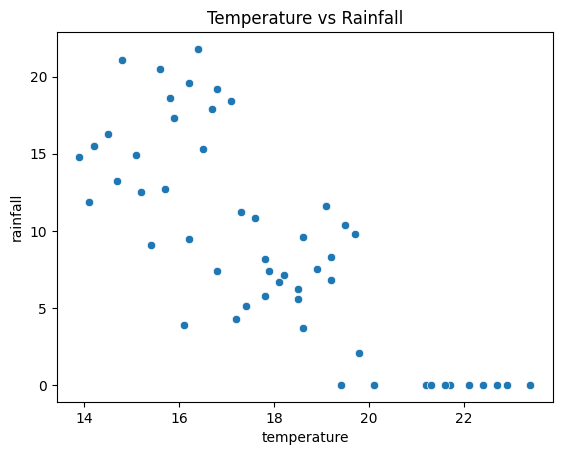

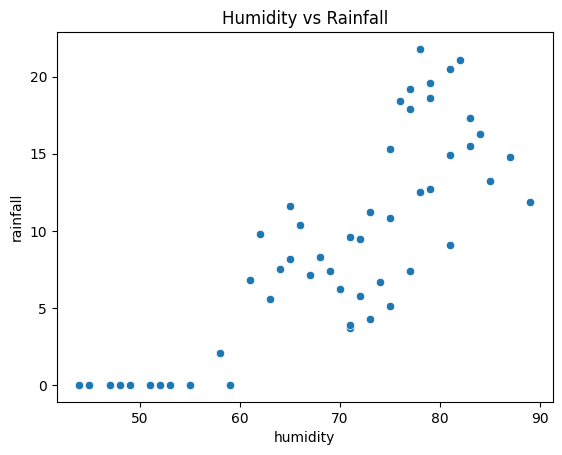

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example relationship plots
sns.scatterplot(x="temperature", y="rainfall", data=df)
plt.title("Temperature vs Rainfall")
plt.show()

sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Humidity vs Rainfall")
plt.show()

## 🧠 Writing Insights (Important)

Based on previous steps, write insights like:

1. Features strongly correlated with rainfall
2. Distribution patterns (skewness, outliers)
3. Important predictors
4. Any anomalies or unusual patterns

## 📝 Example Insights

- Humidity shows strong positive correlation with rainfall  
- Temperature has weak or negative correlation  
- Some features contain outliers (seen in boxplots)  
- Certain variables are right-skewed  
- Dataset may have imbalance in target classes  

#Level 1: Basic (Understanding Data)

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("rainfall_dataset/rainfall.csv")

print("Original shape:", df.shape)
print(df.head())

Original shape: (54, 6)
         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy


In [37]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 54
Number of columns: 6


In [38]:
print(df.columns.tolist())

['date', 'rainfall', 'temperature', 'humidity', 'wind_speed', 'weather_condition']


In [39]:
print(df.dtypes)

date                  object
rainfall             float64
temperature          float64
humidity             float64
wind_speed           float64
weather_condition     object
dtype: object


In [40]:
print(df.isnull().sum())

date                 0
rainfall             1
temperature          1
humidity             1
wind_speed           1
weather_condition    1
dtype: int64


In [41]:
print("Mean:", df["rainfall"].mean())
print("Median:", df["rainfall"].median())
print("Standard Deviation:", df["rainfall"].std())

Mean: 9.049056603773584
Median: 8.3
Standard Deviation: 6.712520524005565


In [42]:
print("Maximum temperature:", df["temperature"].max())
print("Minimum temperature:", df["temperature"].min())

Maximum temperature: 23.4
Minimum temperature: 13.9


In [43]:
numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.head())
print("\nNumerical columns:")
print(numeric_df.columns.tolist())

   rainfall  temperature  humidity  wind_speed
0      12.5         15.2      78.0         8.5
1       8.2         17.8      65.0         5.2
2       0.0         20.1      52.0         3.1
3       3.7         18.6      71.0         6.7
4      21.1         14.8      82.0         9.3

Numerical columns:
['rainfall', 'temperature', 'humidity', 'wind_speed']


In [44]:
corr_matrix = df.select_dtypes(include=np.number).corr()

print(corr_matrix)

             rainfall  temperature  humidity  wind_speed
rainfall     1.000000    -0.790566  0.821357    0.733376
temperature -0.790566     1.000000 -0.966097   -0.902996
humidity     0.821357    -0.966097  1.000000    0.951643
wind_speed   0.733376    -0.902996  0.951643    1.000000


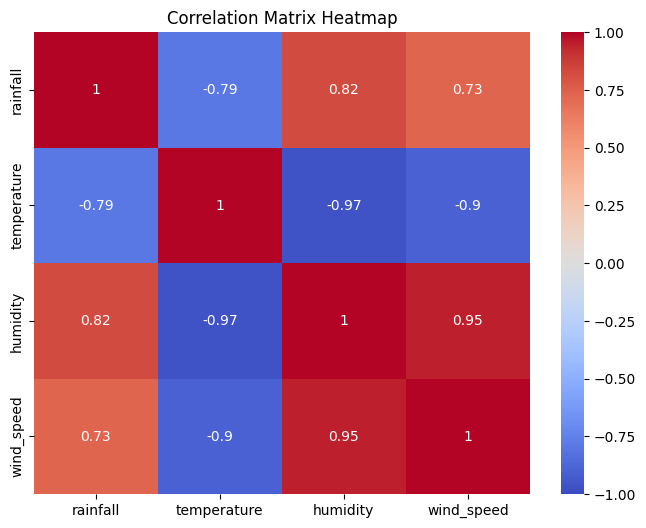

In [45]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix Heatmap")
plt.show()

In [46]:
rainfall_corr = corr_matrix["rainfall"].sort_values(
    ascending=False
)

print(rainfall_corr)

rainfall       1.000000
humidity       0.821357
wind_speed     0.733376
temperature   -0.790566
Name: rainfall, dtype: float64


In [47]:
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):

        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]

        corr_value = corr_matrix.loc[col1, col2]

        if abs(corr_value) > 0.7:
            print(
                col1,
                "and",
                col2,
                ":",
                round(corr_value, 3)
            )

rainfall and temperature : -0.791
rainfall and humidity : 0.821
rainfall and wind_speed : 0.733
temperature and humidity : -0.966
temperature and wind_speed : -0.903
humidity and wind_speed : 0.952


In [48]:
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):

        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]

        value = corr_matrix.loc[col1, col2]

        if abs(value) > 0.7:
            high_corr_pairs.append(
                (col1, col2, round(value, 3))
            )

print(high_corr_pairs)

[('rainfall', 'temperature', np.float64(-0.791)), ('rainfall', 'humidity', np.float64(0.821)), ('rainfall', 'wind_speed', np.float64(0.733)), ('temperature', 'humidity', np.float64(-0.966)), ('temperature', 'wind_speed', np.float64(-0.903)), ('humidity', 'wind_speed', np.float64(0.952))]


In [49]:
upper_triangle = corr_matrix.abs().where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

to_drop = [
    column
    for column in upper_triangle.columns
    if (upper_triangle[column] > 0.7).any()
]

reduced_df = df.drop(columns=to_drop)

print("Dropped columns:", to_drop)
print("Remaining columns:", reduced_df.columns.tolist())

Dropped columns: ['temperature', 'humidity', 'wind_speed']
Remaining columns: ['date', 'rainfall', 'weather_condition']


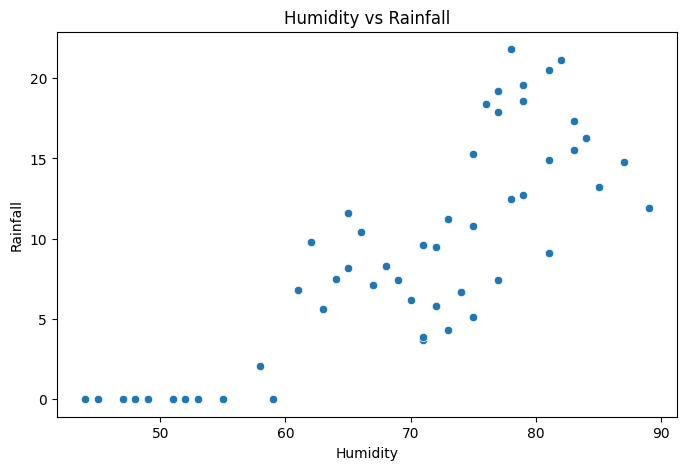

In [50]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="humidity",
    y="rainfall"
)

plt.title("Humidity vs Rainfall")
plt.xlabel("Humidity")
plt.ylabel("Rainfall")

plt.show()

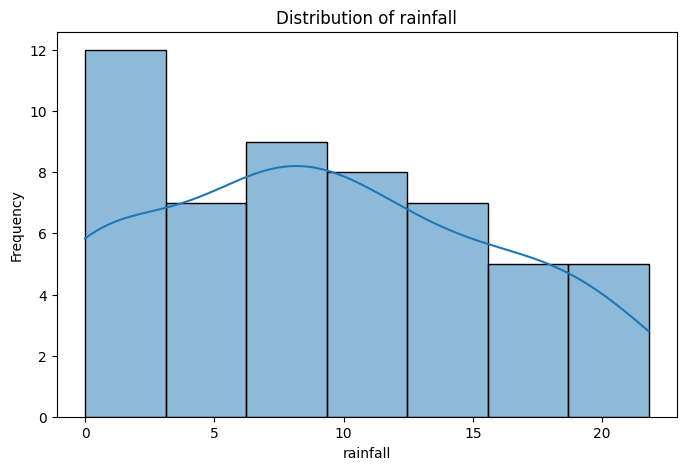

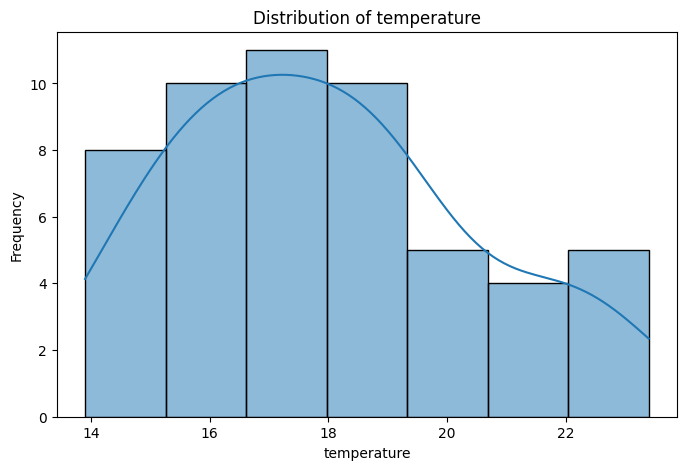

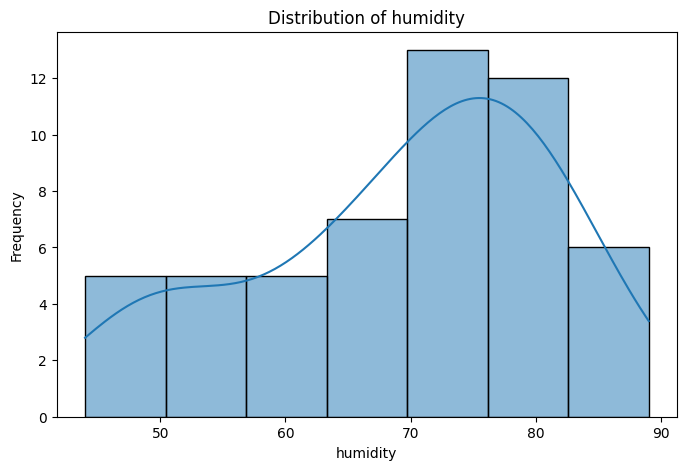

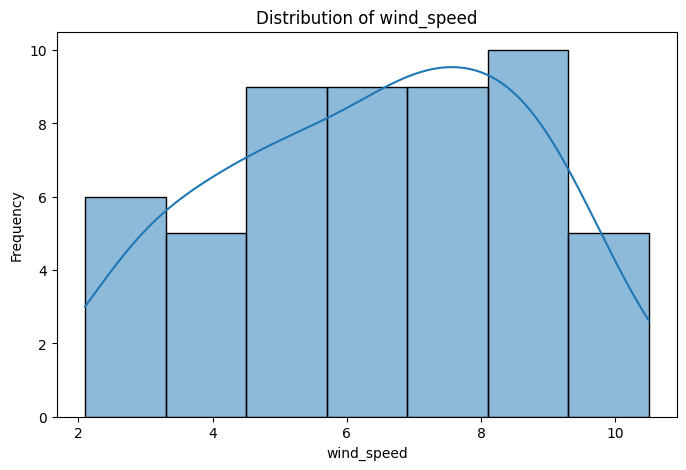

In [51]:
for col in numeric_cols:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

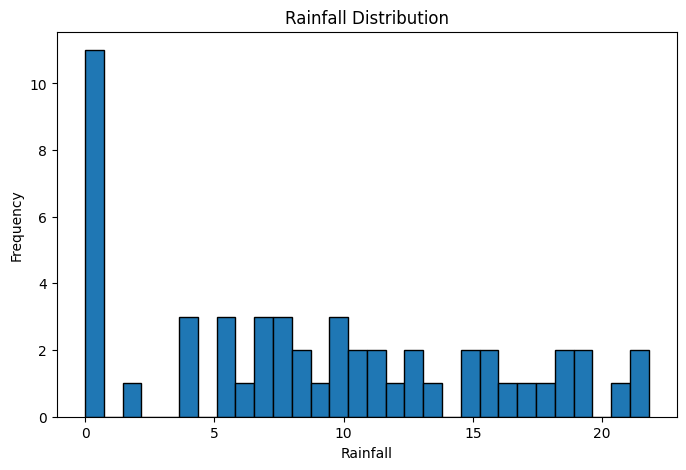

In [52]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["rainfall"],
    bins=30,
    edgecolor="black"
)

plt.title("Rainfall Distribution")
plt.xlabel("Rainfall")
plt.ylabel("Frequency")

plt.show()

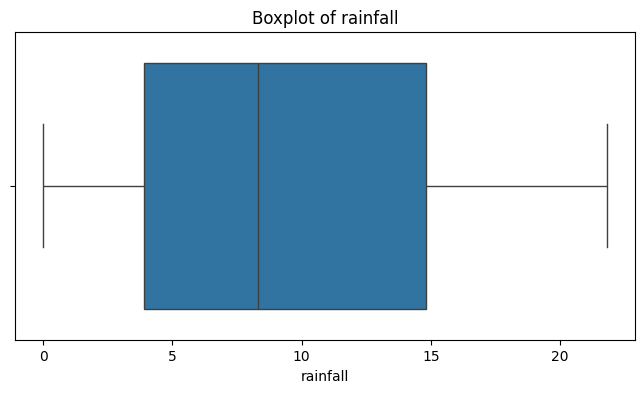

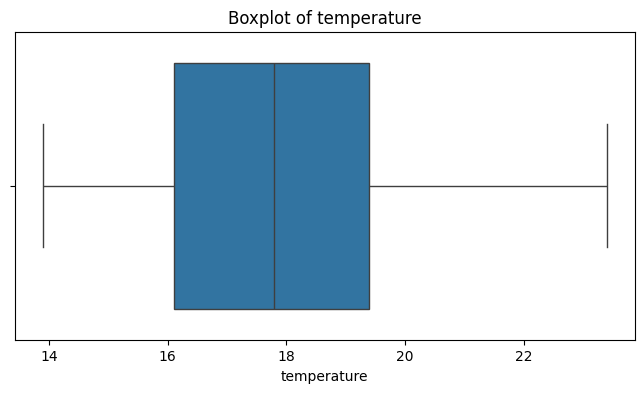

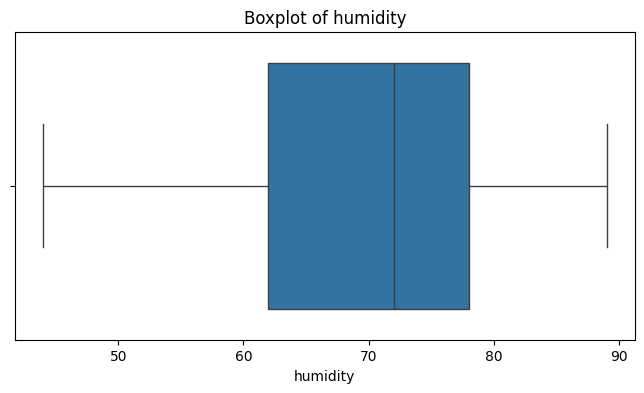

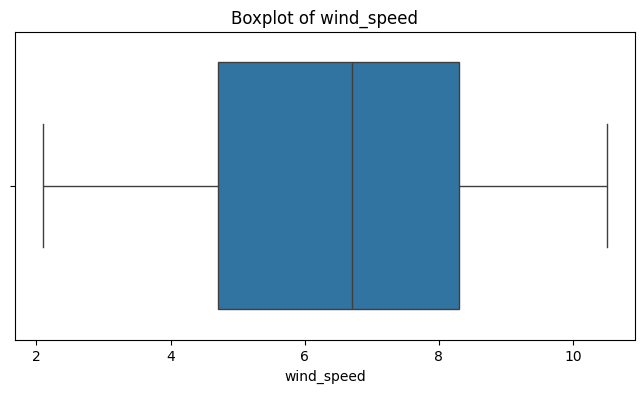

In [53]:
for col in numeric_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()

In [54]:
for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("\nColumn:", col)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Outlier count:", len(outliers))
    print(outliers[[col]])


Column: rainfall
Lower bound: -12.450000000000001
Upper bound: 31.150000000000002
Outlier count: 0
Empty DataFrame
Columns: [rainfall]
Index: []

Column: temperature
Lower bound: 11.150000000000006
Upper bound: 24.349999999999994
Outlier count: 0
Empty DataFrame
Columns: [temperature]
Index: []

Column: humidity
Lower bound: 38.0
Upper bound: 102.0
Outlier count: 0
Empty DataFrame
Columns: [humidity]
Index: []

Column: wind_speed
Lower bound: -0.7000000000000002
Upper bound: 13.700000000000001
Outlier count: 0
Empty DataFrame
Columns: [wind_speed]
Index: []


In [55]:
skew_values = df[numeric_cols].skew()

print(skew_values)

rainfall       0.191925
temperature    0.436075
humidity      -0.564768
wind_speed    -0.207329
dtype: float64


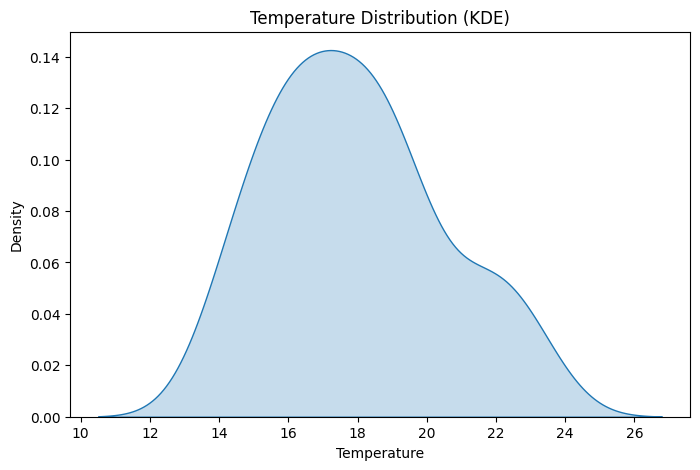

In [56]:
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x="temperature",
    fill=True
)

plt.title("Temperature Distribution (KDE)")
plt.xlabel("Temperature")

plt.show()

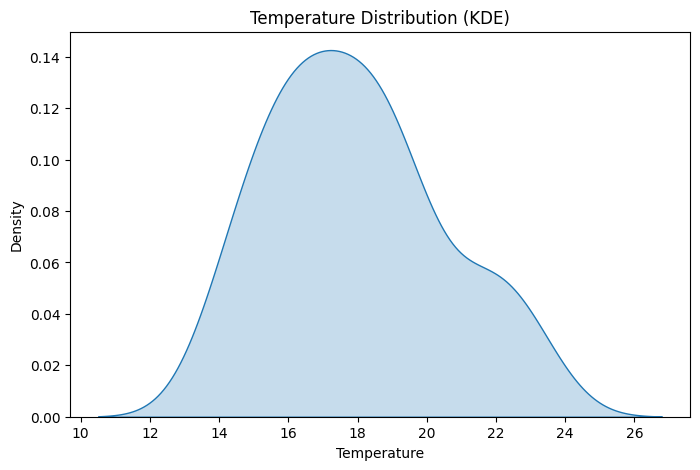

In [57]:
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x="temperature",
    fill=True
)

plt.title("Temperature Distribution (KDE)")
plt.xlabel("Temperature")

plt.show()

In [58]:
mean_rainfall = df["rainfall"].mean()
median_rainfall = df["rainfall"].median()

print("Mean rainfall:", mean_rainfall)
print("Median rainfall:", median_rainfall)

if mean_rainfall > median_rainfall:
    print("Mean is greater than median.")
elif mean_rainfall < median_rainfall:
    print("Mean is less than median.")
else:
    print("Mean and median are equal.")

Mean rainfall: 9.049056603773584
Median rainfall: 8.3
Mean is greater than median.


In [59]:
skew_values = df[numeric_cols].skew()

right_skewed = skew_values[skew_values > 0]

print("Right-skewed features:")
print(right_skewed)

print("Total right-skewed features:", len(right_skewed))

Right-skewed features:
rainfall       0.191925
temperature    0.436075
dtype: float64
Total right-skewed features: 2


In [60]:
avg_rainfall = df.groupby(
    "weather_condition"
)["rainfall"].mean()

print(avg_rainfall)

weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


In [61]:
top_3 = df.nlargest(
    3,
    "rainfall"
)

print(
    top_3[
        [
            "date",
            "rainfall",
            "temperature",
            "humidity",
            "wind_speed",
            "weather_condition"
        ]
    ]
)

          date  rainfall  temperature  humidity  wind_speed weather_condition
29  2022-01-30      21.8         16.4      78.0         7.6             Rainy
4   2022-01-05      21.1         14.8      82.0         9.3             Rainy
44  2022-02-14      20.5         15.6      81.0         8.2             Rainy


In [62]:
average_rainfall = df["rainfall"].mean()

above_average = df[
    df["rainfall"] > average_rainfall
]

print("Average rainfall:", average_rainfall)
print(above_average)

Average rainfall: 9.049056603773584
          date  rainfall  temperature  humidity  wind_speed weather_condition
0   2022-01-01      12.5         15.2      78.0         8.5             Rainy
4   2022-01-05      21.1         14.8      82.0         9.3             Rainy
5   2022-01-06      15.3         16.5      75.0         7.8             Rainy
8   2022-01-09      11.2         17.3      73.0         6.1             Rainy
9   2022-01-10      18.6         15.8      79.0         8.9             Rainy
10  2022-01-11       9.5         16.2      72.0         5.7             Rainy
14  2022-01-15      14.9         15.1      81.0         8.7             Rainy
15  2022-01-16      19.2         16.8      77.0         7.2             Rainy
18  2022-01-19      10.8         17.6      75.0         6.7             Rainy
19  2022-01-20      16.3         14.5      84.0         9.1             Rainy
23  2022-01-24      12.7         15.7      79.0         8.3             Rainy
24  2022-01-25      18.4    

In [63]:
rain_mean = df["rainfall"].mean()

df["rain_group"] = np.where(
    df["rainfall"] > rain_mean,
    "High Rainfall",
    "Low or Equal Rainfall"
)

avg_temperature = df.groupby(
    "rain_group"
)["temperature"].mean()

print(avg_temperature)

rain_group
High Rainfall            16.253846
Low or Equal Rainfall    19.585185
Name: temperature, dtype: float64


In [64]:
rain_mean = df["rainfall"].mean()

df["high_rainfall"] = (
    df["rainfall"] > rain_mean
).astype(int)

print(
    df[
        ["date", "rainfall", "high_rainfall"]
    ].head(10)
)

         date  rainfall  high_rainfall
0  2022-01-01      12.5              1
1  2022-01-02       8.2              0
2  2022-01-03       0.0              0
3  2022-01-04       3.7              0
4  2022-01-05      21.1              1
5  2022-01-06      15.3              1
6  2022-01-07       6.8              0
7  2022-01-08       0.0              0
8  2022-01-09      11.2              1
9  2022-01-10      18.6              1


In [65]:
print(df["high_rainfall"].value_counts().sort_index())

high_rainfall
0    28
1    26
Name: count, dtype: int64


In [66]:
high_rain_df = df[
    df["high_rainfall"] == 1
]

high_rain_corr = high_rain_df[
    numeric_cols
].corr()

print(high_rain_corr)

             rainfall  temperature  humidity  wind_speed
rainfall     1.000000    -0.345569  0.409248    0.324545
temperature -0.345569     1.000000 -0.943597   -0.916880
humidity     0.409248    -0.943597  1.000000    0.940413
wind_speed   0.324545    -0.916880  0.940413    1.000000


In [67]:
def detect_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers


rainfall_outliers = detect_outliers_iqr(
    df,
    "rainfall"
)

print(rainfall_outliers)

Empty DataFrame
Columns: [date, rainfall, temperature, humidity, wind_speed, weather_condition, rain_group, high_rainfall]
Index: []


In [68]:
Q1 = df["rainfall"].quantile(0.25)
Q3 = df["rainfall"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    df["rainfall"].between(
        lower_bound,
        upper_bound
    )
].copy()

print("Original rows:", len(df))
print("Rows after removing outliers:", len(df_no_outliers))
print("Removed rows:", len(df) - len(df_no_outliers))

Original rows: 54
Rows after removing outliers: 53
Removed rows: 1


In [69]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_minmax = df.copy()

df_minmax[numeric_cols] = scaler.fit_transform(
    df[numeric_cols]
)

print(df_minmax[numeric_cols].head())

print("\nMinimum values:")
print(df_minmax[numeric_cols].min())

print("\nMaximum values:")
print(df_minmax[numeric_cols].max())

   rainfall  temperature  humidity  wind_speed
0  0.573394     0.136842  0.755556    0.761905
1  0.376147     0.410526  0.466667    0.369048
2  0.000000     0.652632  0.177778    0.119048
3  0.169725     0.494737  0.600000    0.547619
4  0.967890     0.094737  0.844444    0.857143

Minimum values:
rainfall       0.0
temperature    0.0
humidity       0.0
wind_speed     0.0
dtype: float64

Maximum values:
rainfall       1.0
temperature    1.0
humidity       1.0
wind_speed     1.0
dtype: float64


In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_standardized = df.copy()

df_standardized[numeric_cols] = scaler.fit_transform(
    df[numeric_cols]
)

print(df_standardized[numeric_cols].head())

print("\nColumn means:")
print(df_standardized[numeric_cols].mean().round(4))

print("\nColumn standard deviations:")
print(df_standardized[numeric_cols].std(ddof=0).round(4))

   rainfall  temperature  humidity  wind_speed
0  0.519025    -1.110613  0.738427    0.957999
1 -0.127699    -0.060939 -0.358073   -0.550138
2 -1.360987     0.867619 -1.454573   -1.509862
3 -0.804503     0.262038  0.148004    0.135379
4  1.812474    -1.272101  1.075811    1.323608

Column means:
rainfall       0.0
temperature    0.0
humidity       0.0
wind_speed    -0.0
dtype: float64

Column standard deviations:
rainfall       1.0
temperature    1.0
humidity       1.0
wind_speed     1.0
dtype: float64


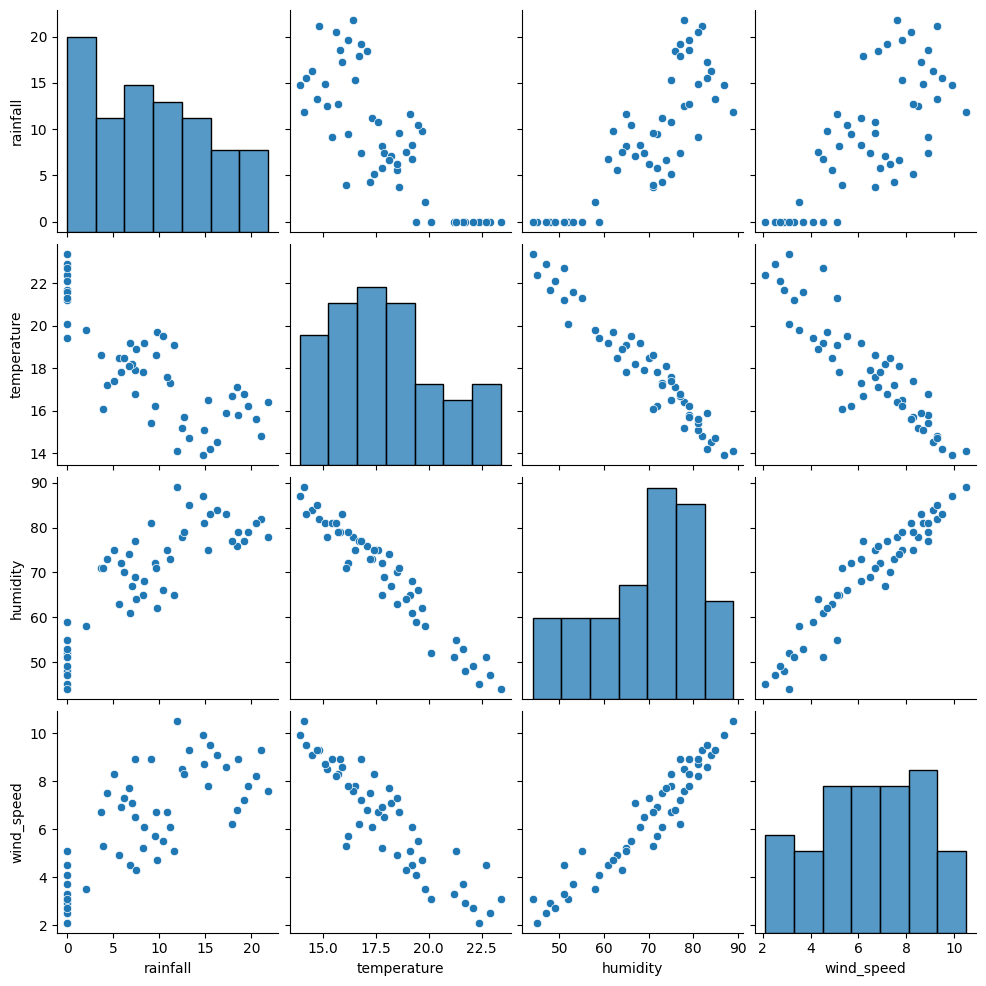

In [71]:
selected_features = [
    "rainfall",
    "temperature",
    "humidity",
    "wind_speed"
]

sns.pairplot(
    df[selected_features]
)

plt.show()

In [72]:
rainfall_corr = df[numeric_cols].corr()["rainfall"]

rainfall_corr = rainfall_corr.drop(
    "rainfall"
)

print("Features with correlation greater than 0.5:")

found = False

for feature, value in rainfall_corr.items():

    if value > 0.5:
        print(
            f"{feature}: correlation = {value:.3f}"
        )
        found = True

if not found:
    print("No features have correlation greater than 0.5.")

Features with correlation greater than 0.5:
humidity: correlation = 0.821
wind_speed: correlation = 0.733


Class counts:
weather_condition
Rainy    42
Sunny    11
Name: count, dtype: int64

Class percentages:
weather_condition
Rainy    79.25
Sunny    20.75
Name: proportion, dtype: float64


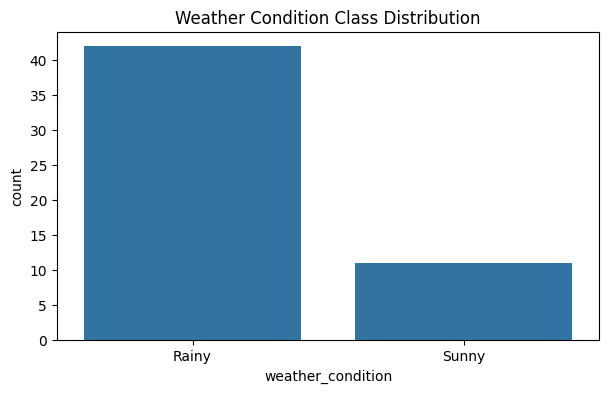

In [73]:
target_counts = df["weather_condition"].value_counts()

target_percentages = (
    df["weather_condition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Class counts:")
print(target_counts)

print("\nClass percentages:")
print(target_percentages)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="weather_condition"
)

plt.title("Weather Condition Class Distribution")
plt.show()

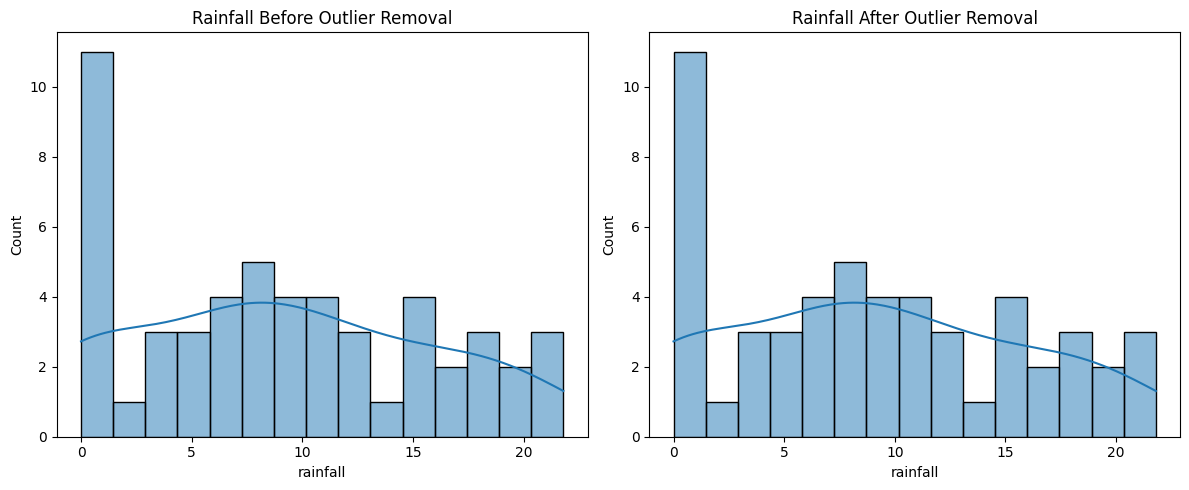

In [74]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

sns.histplot(
    df["rainfall"],
    bins=15,
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    "Rainfall Before Outlier Removal"
)

sns.histplot(
    df_no_outliers["rainfall"],
    bins=15,
    kde=True,
    ax=axes[1]
)

axes[1].set_title(
    "Rainfall After Outlier Removal"
)

plt.tight_layout()
plt.show()

In [75]:
summary_report = pd.DataFrame(
    index=numeric_cols
)

summary_report["mean"] = df[numeric_cols].mean()

summary_report["median"] = df[numeric_cols].median()

summary_report["std_dev"] = df[numeric_cols].std()

summary_report["skewness"] = df[numeric_cols].skew()

summary_report["outlier_count"] = [
    len(detect_outliers_iqr(df, col))
    for col in numeric_cols
]

print(summary_report.round(3))

               mean  median  std_dev  skewness  outlier_count
rainfall      9.049     8.3    6.713     0.192              0
temperature  17.951    17.8    2.501     0.436              0
humidity     69.245    72.0   11.969    -0.565              0
wind_speed    6.404     6.7    2.209    -0.207              0


BASIC DATA INFORMATION
Shape: (54, 8)

Column names:
['date', 'rainfall', 'temperature', 'humidity', 'wind_speed', 'weather_condition', 'rain_group', 'high_rainfall']

Data types:
date                  object
rainfall             float64
temperature          float64
humidity             float64
wind_speed           float64
weather_condition     object
rain_group            object
high_rainfall          int64
dtype: object

Missing values:
date                 0
rainfall             1
temperature          1
humidity             1
wind_speed           1
weather_condition    1
rain_group           0
high_rainfall        0
dtype: int64

DESCRIPTIVE STATISTICS
        rainfall  temperature   humidity  wind_speed  high_rainfall
count  53.000000    53.000000  53.000000   53.000000      54.000000
mean    9.049057    17.950943  69.245283    6.403774       0.481481
std     6.712521     2.500663  11.969361    2.209069       0.504349
min     0.000000    13.900000  44.000000    2.100000       0.000

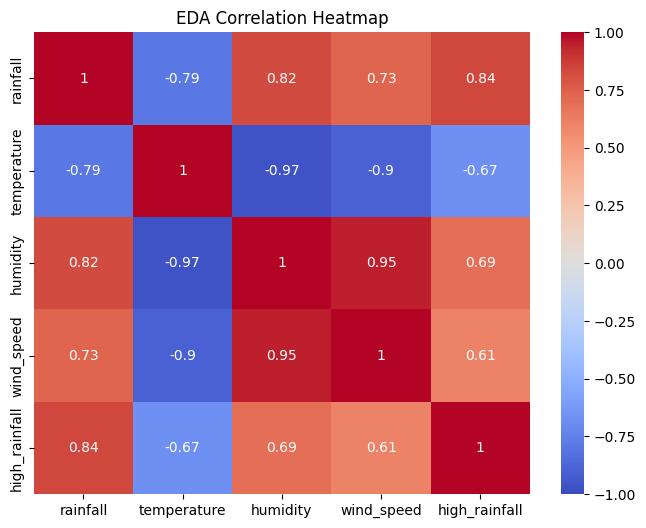


SKEWNESS ANALYSIS
rainfall         0.191925
temperature      0.436075
humidity        -0.564768
wind_speed      -0.207329
high_rainfall    0.076260
dtype: float64


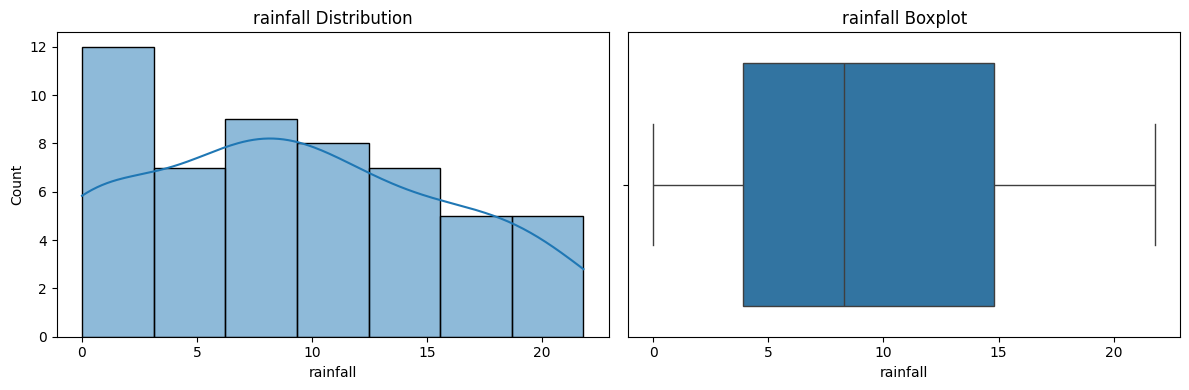

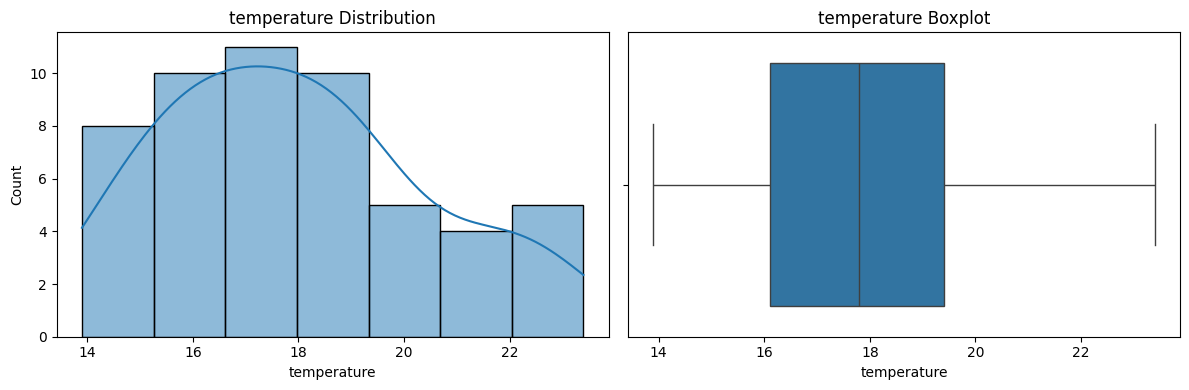

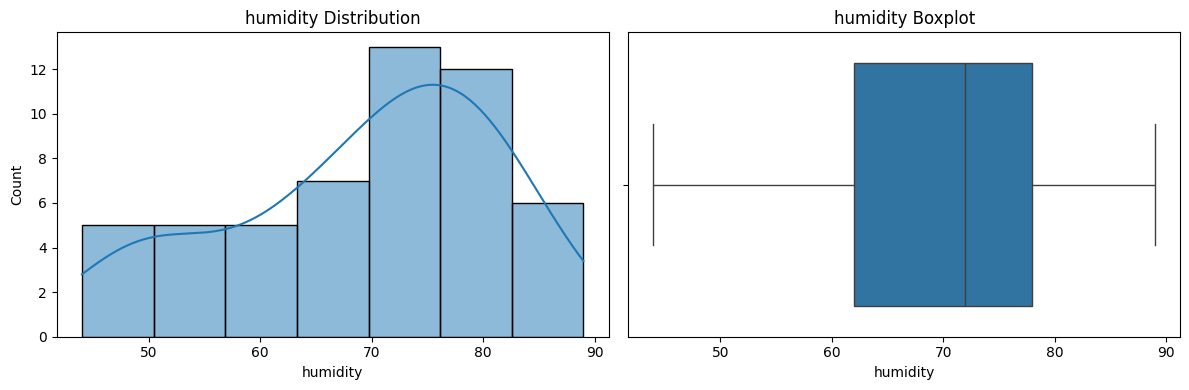

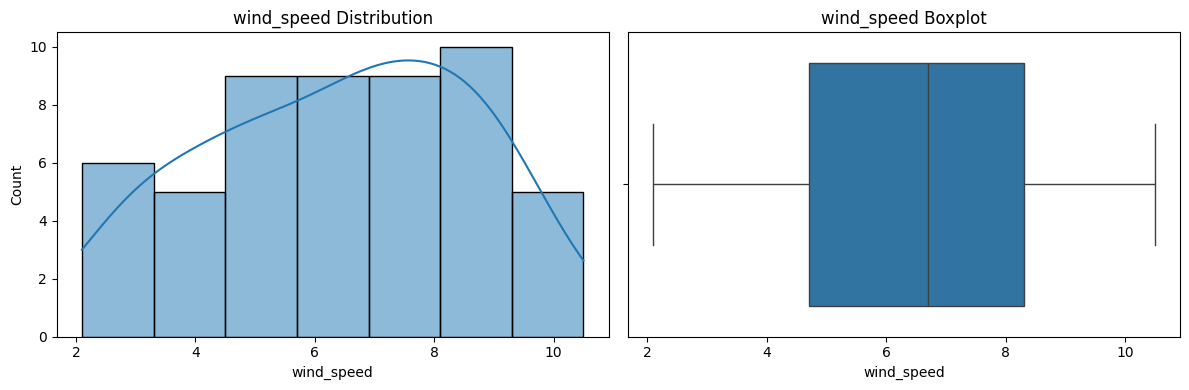

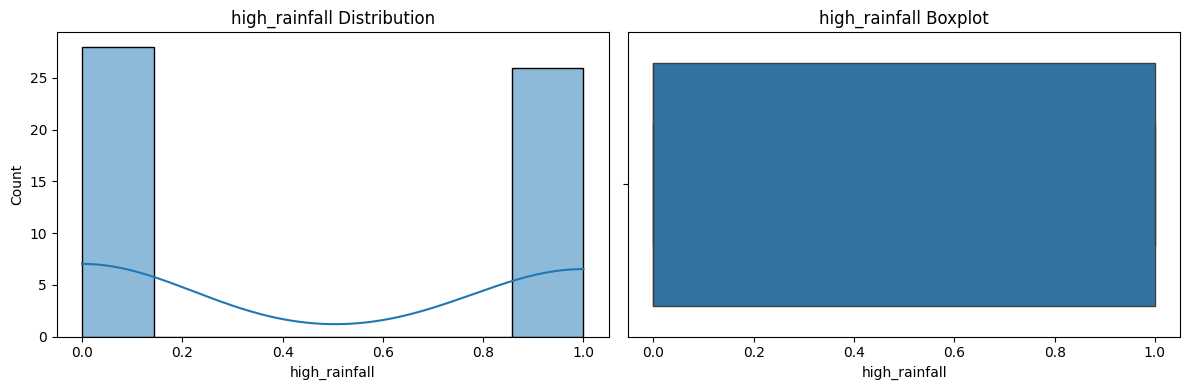


RAINFALL INSIGHTS
Average rainfall: 9.049056603773584
Maximum rainfall: 21.8
Minimum rainfall: 0.0

Correlation with rainfall:
high_rainfall    0.841399
humidity         0.821357
wind_speed       0.733376
temperature     -0.790566
Name: rainfall, dtype: float64


In [76]:
def full_eda(data):

    numeric_data = data.select_dtypes(
        include=np.number
    )

    # 1. Basic information
    print("=" * 50)
    print("BASIC DATA INFORMATION")
    print("=" * 50)

    print("Shape:", data.shape)

    print("\nColumn names:")
    print(data.columns.tolist())

    print("\nData types:")
    print(data.dtypes)

    print("\nMissing values:")
    print(data.isnull().sum())

    # 2. Descriptive statistics
    print("\n" + "=" * 50)
    print("DESCRIPTIVE STATISTICS")
    print("=" * 50)

    print(numeric_data.describe())

    # 3. Correlation analysis
    print("\n" + "=" * 50)
    print("CORRELATION MATRIX")
    print("=" * 50)

    corr = numeric_data.corr()

    print(corr)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    plt.title("EDA Correlation Heatmap")
    plt.show()

    # 4. Distribution analysis
    print("\n" + "=" * 50)
    print("SKEWNESS ANALYSIS")
    print("=" * 50)

    print(numeric_data.skew())

    for col in numeric_data.columns:

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(12, 4)
        )

        sns.histplot(
            data=data,
            x=col,
            kde=True,
            ax=axes[0]
        )

        axes[0].set_title(
            f"{col} Distribution"
        )

        sns.boxplot(
            data=data,
            x=col,
            ax=axes[1]
        )

        axes[1].set_title(
            f"{col} Boxplot"
        )

        plt.tight_layout()
        plt.show()

    # 5. Rainfall-specific insights
    if "rainfall" in numeric_data.columns:

        print("\n" + "=" * 50)
        print("RAINFALL INSIGHTS")
        print("=" * 50)

        print(
            "Average rainfall:",
            data["rainfall"].mean()
        )

        print(
            "Maximum rainfall:",
            data["rainfall"].max()
        )

        print(
            "Minimum rainfall:",
            data["rainfall"].min()
        )

        rainfall_corr = corr["rainfall"].drop(
            "rainfall"
        )

        print("\nCorrelation with rainfall:")
        print(rainfall_corr.sort_values(
            ascending=False
        ))

    return {
        "shape": data.shape,
        "missing_values": data.isnull().sum(),
        "statistics": numeric_data.describe(),
        "correlation": corr,
        "skewness": numeric_data.skew()
    }


# Run complete EDA
eda_results = full_eda(df)